# Exploratory Data Analysis (EDA)

In the second stage of the machine learning pipeline we undertake EDA in two forms. First a statistical exploration to identify any skewness in data, the range of values, any missing values, any duplicates and unique values. Through visual exploration we can identify outliers, and visual patterns.

## Case-Study 01: Malta International Airport passenger movements

### Data acquisition

In [5]:
# Loading libraries
import pandas as pd
import os.path as osp

In [6]:
# Load the dataset
df = pd.read_csv(osp.join('..', 'data', 'mia', 'miaPassengers.txt'), sep='\t')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 19 entries, 0 to 18
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   year        19 non-null     int64
 1   passengers  19 non-null     int64
dtypes: int64(2)
memory usage: 436.0 bytes


In [7]:
# Preview the start of the date
df.head()

,year,passengers
0,2005,2397049
1,2006,2696034
2,2007,2974501
3,2008,3109868
4,2009,2918664


In [8]:
# Preview the end of the date
df.tail()

,year,passengers
14,2019,7310289
15,2020,1748050
16,2021,2540335
17,2022,5851079
18,2023,7803042


This dataset appears to be a complete dataset (no missing values), made up of 19 observations/rows and 2 variables/column. These are both 64-bit integers taking a total of 438 bytes of memory. It also appears to be a temporal dataset witg a range of years from 2005 till 2023, focusing on passenger movements in the Malta International Airport. Therefore this appears to be a labelled dataset, making it a supervised machine learning problem, with the focus being on predicting future momements. Moving forward we should focus on:
1. Confirming the range of values
2. Confirm any data issues such as missing values or duplicates
3. Visualise the dataset to observe any patterns prior to data modelling.

## Exploratory Data Analysis

In [9]:
# Statistical EDA
df.describe()

,year,passengers
count,19.000000,1.900000e+01
mean,2014.000000,4.244323e+06
std,5.627314,1.773922e+06
min,2005.000000,1.748050e+06
25%,2009.500000,2.946582e+06
50%,2014.000000,3.649938e+06
75%,2018.500000,5.465575e+06
max,2023.000000,7.803042e+06


From this output we can confirm that the dataset is actually sorted ranging from 2005 till 2023. We also confirm that there are no values such as 0 or -ve used to represent missing data.

In [10]:
# Checking for data issues
# Check for nulls
df.isnull().sum()

year          0
passengers    0
dtype: int64

In [11]:
# Checking for duplicated rows.
df.duplicated().sum()

np.int64(0)

Following these last 2 checks we can confirm that till now there does not appear to be any issues with the data, no missing no duplicates

In [12]:
# Visual exploration, some additional libraries are needed
import matplotlib.pyplot as plt
import seaborn as sns

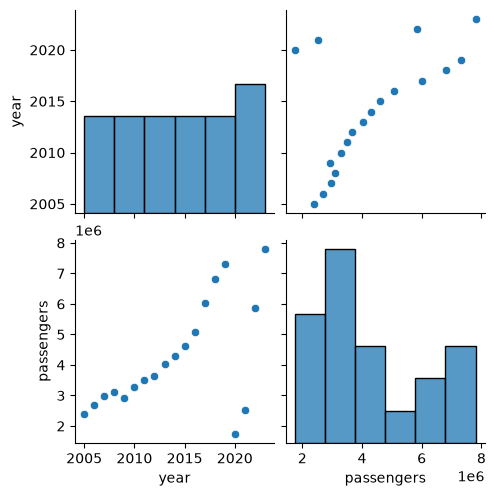

In [13]:
# Starting with a pairplot
sns.pairplot(data=df)

The seaborn pairplot has the benefit of providing a quick visual for all variables in the form of histogram, then scatterplates for ever paring of all variables. Note that the visual is a flipped mirror image across the diagonal. The downside of this visual is that you will get a lot of visuals that might be uneccesary, as well as it might be crammed. Yet it provides a quick visual glance at the data

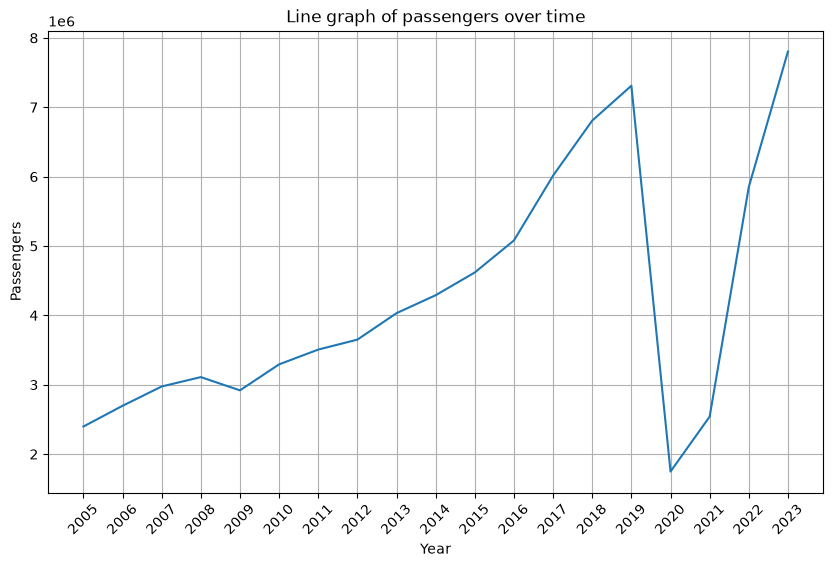

In [17]:
# Generating a line chart.
plt.figure(figsize=(10,6))
plt.plot(df['year'],df['passengers'])
plt.title('Line graph of passengers over time')
plt.xlabel('Year')
plt.ylabel('Passengers')
plt.xticks(df['year'], rotation=45)
plt.grid(True)
plt.show()

From this visual we can observe that there are a numnber of events that merit further investigation:
1. The 2008 and subsequent years, dip. Possibly attributed to the 2008 global recession. The market appears to have taken till 2013 to recover fully.
2. The radical steep growth in the movements from 2016, or thereof. An investigation on whether there was key investment or changes thereabout.
3. The 2019/2020 dip, which is most likely attributed to the global COVID-19 pandemic. We observe that the market started to recover in 2021 and recovered very quickly, yet not to pre 2020 levels by 2023.

Recommendation for moving forward, to undertake predictions past 2025. It is recommended to obtain additional information, in particular movements for 2024 and 2025.